In [1]:
#Load packages
import pandas as pd
import numpy as np
import textwrap
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, Circle, Patch
from scipy.stats import mannwhitneyu
import matplotlib.colors as mcolors

In [2]:
#checking my packages version
import sys
import scipy
import matplotlib
print("Python:", sys.version)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)

Python: 3.11.8 | packaged by conda-forge | (main, Feb 16 2024, 20:53:32) [GCC 12.3.0]
pandas: 2.2.3
NumPy: 1.26.4
SciPy: 1.15.2
Matplotlib: 3.10.0


In [3]:
#load data
data = pd.read_excel("/home/jemima/Traumacare_collected_responses.xlsx")

In [4]:
data

,paper_form_id,consent_included,have_attended_trauma-focused AP?,Ethnic_group,Session_attended,Gender,age_group,learning_disability_reported,pre_anatomical_relationships,pre_vessels_landmarks,...,Use_knowledge_in_practice,prepared_to_apply_concept_freetext,q_overall_comments_text,tutor_clarity,tutor_student_participation,tutor_responsiveness,tutor_guidance,tutor_engagement,entered_by,data_entry_checked
0,THORAX AND LIMBS SESSION Organised by JEMIMA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,Yes,No,White british,Thorax and limbs,Female,Prefer not to say,No,3,2,...,5.0,the location of anatomical structures into rea...,Thank you,5.0,5.0,5.0,5.0,5.0,JCS,TA
2,2,Yes,No,White british,Thorax and limbs,Female,Prefer not to say,No,3,1,...,4.0,Manipulation of joints,Excellent session,5.0,5.0,5.0,5.0,5.0,JCS,TA
3,3,Yes,No,other white,Thorax and limbs,Female,26-30,No,2,2,...,5.0,NaN,NaN,5.0,5.0,5.0,5.0,5.0,JCS,TA
4,4,Yes,No,Indian,Thorax and limbs,Female,Prefer not to say,No,3,3,...,5.0,NaN,NaN,5.0,5.0,5.0,5.0,5.0,JCS,TA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,13,Yes,No,African,Neuroscience,Female,26-30,No,4,2,...,5.0,Brain and spinal cord,NaN,5.0,5.0,5.0,5.0,5.0,JCS,IE
72,14,Yes,No,Indian,Neuroscience,Male,31-35,No,3,3,...,5.0,Common bleed location and correlation of theirs,Very good session. Should be a full day!,5.0,5.0,5.0,5.0,5.0,JCS,IE
73,15,Yes,No,Indian,Neuroscience,Female,26-30,No,2,2,...,5.0,Knolwedge gained,Nil,5.0,5.0,5.0,5.0,5.0,JCS,IE
74,16,Yes,No,Any other Asian,Neuroscience,Female,>46,No,3,2,...,3.0,Anatomage + Physio,NaN,4.0,4.0,4.0,4.0,4.0,JCS,IE


In [5]:
#Excluding those that did not consent and lecturers
data["consent_included"] = data["consent_included"].astype(str).str.strip()
data["Session_attended"] = data["Session_attended"].astype(str).str.strip()

analysis_data = data[(data["consent_included"].str.lower() == "yes") &
    (~data["Session_attended"].str.lower().str.contains("lecturer", na=False))
].copy()

In [6]:
analysis_data

,paper_form_id,consent_included,have_attended_trauma-focused AP?,Ethnic_group,Session_attended,Gender,age_group,learning_disability_reported,pre_anatomical_relationships,pre_vessels_landmarks,...,Use_knowledge_in_practice,prepared_to_apply_concept_freetext,q_overall_comments_text,tutor_clarity,tutor_student_participation,tutor_responsiveness,tutor_guidance,tutor_engagement,entered_by,data_entry_checked
1,1,Yes,No,White british,Thorax and limbs,Female,Prefer not to say,No,3,2,...,5.0,the location of anatomical structures into rea...,Thank you,5.0,5.0,5.0,5.0,5.0,JCS,TA
2,2,Yes,No,White british,Thorax and limbs,Female,Prefer not to say,No,3,1,...,4.0,Manipulation of joints,Excellent session,5.0,5.0,5.0,5.0,5.0,JCS,TA
3,3,Yes,No,other white,Thorax and limbs,Female,26-30,No,2,2,...,5.0,NaN,NaN,5.0,5.0,5.0,5.0,5.0,JCS,TA
4,4,Yes,No,Indian,Thorax and limbs,Female,Prefer not to say,No,3,3,...,5.0,NaN,NaN,5.0,5.0,5.0,5.0,5.0,JCS,TA
5,5,Yes,No,White and Black Caribbean,Thorax and limbs,Female,21-25,No,4,2,...,5.0,NaN,NaN,5.0,5.0,5.0,4.0,5.0,JCS,TA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,13,Yes,No,African,Neuroscience,Female,26-30,No,4,2,...,5.0,Brain and spinal cord,NaN,5.0,5.0,5.0,5.0,5.0,JCS,IE
72,14,Yes,No,Indian,Neuroscience,Male,31-35,No,3,3,...,5.0,Common bleed location and correlation of theirs,Very good session. Should be a full day!,5.0,5.0,5.0,5.0,5.0,JCS,IE
73,15,Yes,No,Indian,Neuroscience,Female,26-30,No,2,2,...,5.0,Knolwedge gained,Nil,5.0,5.0,5.0,5.0,5.0,JCS,IE
74,16,Yes,No,Any other Asian,Neuroscience,Female,>46,No,3,2,...,3.0,Anatomage + Physio,NaN,4.0,4.0,4.0,4.0,4.0,JCS,IE


In [7]:
# Clean variables for Participants Table
analysis_data["age_group"] = (analysis_data["age_group"]
    .replace({"nan": np.nan}) .fillna("Missing"))

analysis_data["learning_disability_reported"] = (analysis_data["learning_disability_reported"]
    .replace({"nan": np.nan}) .fillna("Missing"))

analysis_data["have_attended_trauma-focused AP?"] = (analysis_data["have_attended_trauma-focused AP?"]
    .replace({"nan": np.nan}) .fillna("Missing"))

analysis_data["Gender"] = (analysis_data["Gender"]
    .replace({"nan": np.nan}) .fillna("Missing"))

In [8]:
analysis_data

,paper_form_id,consent_included,have_attended_trauma-focused AP?,Ethnic_group,Session_attended,Gender,age_group,learning_disability_reported,pre_anatomical_relationships,pre_vessels_landmarks,...,Use_knowledge_in_practice,prepared_to_apply_concept_freetext,q_overall_comments_text,tutor_clarity,tutor_student_participation,tutor_responsiveness,tutor_guidance,tutor_engagement,entered_by,data_entry_checked
1,1,Yes,No,White british,Thorax and limbs,Female,Prefer not to say,No,3,2,...,5.0,the location of anatomical structures into rea...,Thank you,5.0,5.0,5.0,5.0,5.0,JCS,TA
2,2,Yes,No,White british,Thorax and limbs,Female,Prefer not to say,No,3,1,...,4.0,Manipulation of joints,Excellent session,5.0,5.0,5.0,5.0,5.0,JCS,TA
3,3,Yes,No,other white,Thorax and limbs,Female,26-30,No,2,2,...,5.0,NaN,NaN,5.0,5.0,5.0,5.0,5.0,JCS,TA
4,4,Yes,No,Indian,Thorax and limbs,Female,Prefer not to say,No,3,3,...,5.0,NaN,NaN,5.0,5.0,5.0,5.0,5.0,JCS,TA
5,5,Yes,No,White and Black Caribbean,Thorax and limbs,Female,21-25,No,4,2,...,5.0,NaN,NaN,5.0,5.0,5.0,4.0,5.0,JCS,TA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,13,Yes,No,African,Neuroscience,Female,26-30,No,4,2,...,5.0,Brain and spinal cord,NaN,5.0,5.0,5.0,5.0,5.0,JCS,IE
72,14,Yes,No,Indian,Neuroscience,Male,31-35,No,3,3,...,5.0,Common bleed location and correlation of theirs,Very good session. Should be a full day!,5.0,5.0,5.0,5.0,5.0,JCS,IE
73,15,Yes,No,Indian,Neuroscience,Female,26-30,No,2,2,...,5.0,Knolwedge gained,Nil,5.0,5.0,5.0,5.0,5.0,JCS,IE
74,16,Yes,No,Any other Asian,Neuroscience,Female,>46,No,3,2,...,3.0,Anatomage + Physio,NaN,4.0,4.0,4.0,4.0,4.0,JCS,IE


## Table 3 (Participants Demographics) calulation

In [8]:
# Table 3: participant characteristics, n (%)
def fmt_table(var, label):
    tab = pd.crosstab(analysis_data[var], analysis_data["Session_attended"])
    tab["Overall"] = analysis_data[var].value_counts()
    tab = tab[["Overall"] + [c for c in tab.columns if c != "Overall"]]

    # Denominators for %: Overall % uses total sample size & session % use the number of learners in each session.
    denominators = {"Overall": len(analysis_data)}
    denominators.update(analysis_data["Session_attended"].value_counts().to_dict())

    # Convert counts to n (%) format
    out = tab.copy()
    for col in out.columns:
        out[col] = out[col].apply(lambda x: f"{x} ({x / denominators[col] * 100:.1f})")

    # Add table labels
    out.insert(0, "Demographics", "")
    out.insert(1, "Category", out.index)
    # Show the demographics name only once for each section
    out.iloc[0, out.columns.get_loc("Demographics")] = label
    return out.reset_index(drop=True)


table3 = pd.concat([
    fmt_table("Session_attended", "Session attended"),
    fmt_table("age_group", "Age group, years"),
    fmt_table("Gender", "Gender"),
    fmt_table("learning_disability_reported", "Reported learning disability"),
    fmt_table("have_attended_trauma-focused AP?", "Previous trauma-focused anatomy practical")
], ignore_index=True)

In [9]:
display(table3)

Session_attended,Demographics,Category,Overall,Neuroscience,Thorax and limbs
0,Session attended,Neuroscience,35 (51.5),35 (100.0),0 (0.0)
1,,Thorax and limbs,33 (48.5),0 (0.0),33 (100.0)
2,"Age group, years",21-25,6 (8.8),1 (2.9),5 (15.2)
3,,26-30,17 (25.0),9 (25.7),8 (24.2)
4,,31-35,17 (25.0),10 (28.6),7 (21.2)
5,,36-40,12 (17.6),7 (20.0),5 (15.2)
6,,41-45,4 (5.9),4 (11.4),0 (0.0)
7,,>46,8 (11.8),3 (8.6),5 (15.2)
8,,Missing,1 (1.5),1 (2.9),0 (0.0)
9,,Prefer not to say,3 (4.4),0 (0.0),3 (9.1)


In [10]:
#export the table
table3.to_excel("Table3_participant_demographics_Traumacare.xlsx", index=False)

## Figure 2 Stats: Learner-reported anatomical knowledge gain

In [9]:
# Figure 2: Learner-reported anatomical knowledge gain
# Set the exact session names here
thorax_session = "Thorax and limbs"
neuro_session = "Neuroscience"

# Columns used for the three main anatomy domains
knowledge_items = {"Thorax and limbs": {
        "Thoracoabdominal organ\nidentification and relations": ("pre_anatomical_relationships", "post_anatomical_relationships"),
        "Identification of Limb vessels\nand fracture landmarks": ("pre_vessels_landmarks", "post_vessels_landmarks"),
        "Joint movement and\nassociated injury risk": ("pre_joint_movement_injury_risk", "post_joint_movement_injury_risk")
    },
    "Neuroscience": {
        "Vertebral anatomy and\nfracture stability": ("pre_anatomical_relationships", "post_anatomical_relationships"),
        "Cranial cavity, cranial\nnerves and raised ICP": ("pre_vessels_landmarks", "post_vessels_landmarks"),
        "Protective layers, bleeding sites\nand neurotrauma correlation": ("pre_joint_movement_injury_risk", "post_joint_movement_injury_risk")
    }
}
# function to extract clean numeric pre/post values since it was in Likert rating
def get_values(df, pre_col, post_col):
    pre = pd.to_numeric(df[pre_col], errors="coerce").dropna()
    post = pd.to_numeric(df[post_col], errors="coerce").dropna()
    return pre, post

# function to format p-values in my future figures
def p_label(p):
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "ns"

In [10]:
# Function to draw one session panel
def plot_session(ax, df, session_name, title):
    session_df = df[df["Session_attended"] == session_name]

    positions, labels, all_values = [], [], []
    pvals = []
    x = 1

    for domain, (pre_col, post_col) in knowledge_items[session_name].items():
        pre, post = get_values(session_df, pre_col, post_col)

        all_values.extend([pre, post])
        positions.extend([x, x + 0.45])
        labels.append(domain)

        # Mann-Whitney U test because pre/post responses are not matched
        _, p = mannwhitneyu(pre, post, alternative="two-sided")
        pvals.append((x, x + 0.45, p))

        x += 1.35
    
    # Boxplots
    bp = ax.boxplot(all_values, positions=positions, widths=0.35, patch_artist=True, showfliers=False)

    # Colour the boxes: first box in each pair = Pre, second box = Post
    for i, box in enumerate(bp["boxes"]):
        if i % 2 == 0:
            box.set_facecolor("blue")   # Pre-rating
        else:
            box.set_facecolor("orange")      # Post-rating
        
    # Jittered individual points
    for pos, vals in zip(positions, all_values):
        jitter = np.random.normal(pos, 0.06, size=len(vals))
        ax.scatter(jitter, vals, color="grey", alpha=0.5, s=18)

    # Add p-value brackets
    for x1, x2, p in pvals:
        y = 5.25
        ax.plot([x1, x1, x2, x2], [y - 0.05, y, y, y - 0.05], linewidth=1, color="black")
        ax.text((x1 + x2) / 2, y + 0.03, p_label(p), ha="center", fontsize=9)

    # Axis formatting
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_ylim(0.8, 5.6)
    ax.set_yticks([1, 2, 3, 4, 5])
    ax.set_ylabel("Self-rated anatomical knowledge gain")
    ax.set_xticks([(positions[i] + positions[i + 1]) / 2 for i in range(0, len(positions), 2)])
    ax.set_xticklabels(labels, rotation=0, fontsize=9, ha="center")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(handles=[
        plt.Rectangle((0, 0), 1, 1, color="blue", label="Pre-rating"),
        plt.Rectangle((0, 0), 1, 1, color="orange", label="Post-rating")],frameon=False, fontsize=7)

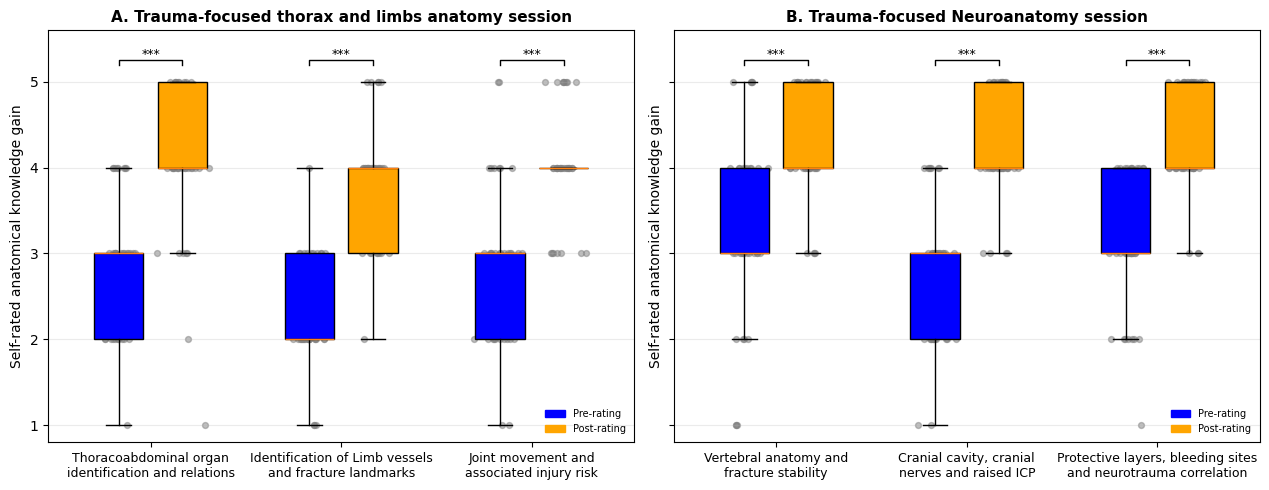

In [11]:
#Create two-panel figure
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

plot_session(axes[0], analysis_data, thorax_session, "A. Trauma-focused thorax and limbs anatomy session")
plot_session(axes[1], analysis_data, neuro_session, "B. Trauma-focused Neuroanatomy session")

plt.tight_layout()
#plt.savefig("Figure2_knowledge_gain_boxplots.png", dpi=600, bbox_inches="tight")
#plt.savefig("Figure2_knowledge_gain_boxplots.pdf", bbox_inches="tight")
plt.show()

In [12]:
analysis_data["Session_attended"].value_counts(dropna=False)

Session_attended
Neuroscience        35
Thorax and limbs    33
Name: count, dtype: int64

In [13]:
#checking why joint movement and injury risk collapsed
joint_cols = ["pre_joint_movement_injury_risk", "post_joint_movement_injury_risk"]

analysis_data.groupby("Session_attended")[joint_cols].describe()

pre_joint_movement_injury_risk                  \
                                          count unique top freq   
Session_attended                                                  
Neuroscience                                 35      4   3   16   
Thorax and limbs                             33      5   3   13   

                 post_joint_movement_injury_risk                  
                                           count unique top freq  
Session_attended                                                  
Neuroscience                                  35      3   4   17  
Thorax and limbs                              33      3   4   18

In [15]:
# Summary statistics and raw p-values for knowledge domains
def p_star(p):
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "ns"
       
rows = []

for session, domains in knowledge_items.items():
    session_df = analysis_data[analysis_data["Session_attended"] == session]

    for domain, (pre_col, post_col) in domains.items():
        pre = pd.to_numeric(session_df[pre_col], errors="coerce").dropna()
        post = pd.to_numeric(session_df[post_col], errors="coerce").dropna()

        u_stat, p = mannwhitneyu(pre, post, alternative="two-sided")

        # Rank-biserial effect size. # Positive value means post-ratings tended to be higher than pre-ratings
        effect_size = 1 - (2 * u_stat) / (len(pre) * len(post))
        
        rows.append({
            "Session": session, "Domain": domain,
            "Pre n": len(pre), "Post n": len(post),
            "Pre median": pre.median(), "Pre Q1": pre.quantile(0.25), "Pre Q3": pre.quantile(0.75),
            "Post median": post.median(), "Post Q1": post.quantile(0.25), "Post Q3": post.quantile(0.75),
            "Pre ≥4 n": (pre >= 4).sum(), "Pre ≥4 %": round((pre >= 4).mean() * 100, 1),
            "Post ≥4 n": (post >= 4).sum(), "Post ≥4 %": round((post >= 4).mean() * 100, 1),
            "Mann-Whitney U": u_stat, "Raw p-value": p, "Rank-biserial effect size": effect_size,
            "Figure label": p_star(p)
        })

knowledge_stats = pd.DataFrame(rows)

display(knowledge_stats)

knowledge_stats.to_excel("Knowledge_gain_stats_summary.xlsx", index=False)

,Session,Domain,Pre n,Post n,Pre median,Pre Q1,Pre Q3,Post median,Post Q1,Post Q3,Pre ≥4 n,Pre ≥4 %,Post ≥4 n,Post ≥4 %,Mann-Whitney U,Raw p-value,Rank-biserial effect size,Figure label
0,Thorax and limbs,Thoracoabdominal organ\nidentification and rel...,33,33,3.0,2.0,3.0,4.0,4.0,5.0,8,24.2,26,78.8,202.5,4.673511e-06,0.628099,***
1,Thorax and limbs,Identification of Limb vessels\nand fracture l...,33,33,2.0,2.0,3.0,4.0,3.0,4.0,1,3.0,24,72.7,78.0,5.036027e-10,0.856749,***
2,Thorax and limbs,Joint movement and\nassociated injury risk,33,33,3.0,2.0,3.0,4.0,4.0,4.0,8,24.2,26,78.8,199.5,3.971889e-06,0.633609,***
3,Neuroscience,Vertebral anatomy and\nfracture stability,35,35,3.0,3.0,4.0,4.0,4.0,5.0,15,42.9,31,88.6,283.5,5.285896e-05,0.537143,***
4,Neuroscience,"Cranial cavity, cranial\nnerves and raised ICP",35,35,3.0,2.0,3.0,4.0,4.0,5.0,7,20.0,31,88.6,126.0,2.494469e-09,0.794286,***
5,Neuroscience,"Protective layers, bleeding sites\nand neurotr...",35,35,3.0,3.0,4.0,4.0,4.0,5.0,11,31.4,32,91.4,150.5,1.218232e-08,0.754286,***


In [16]:
#correcting for p value using Holm-adjusted p-values for the six knowledge comparisons
pvals = knowledge_stats["Raw p-value"].values
m = len(pvals)

order = np.argsort(pvals)
ranked_p = pvals[order]

holm = np.empty(m)
running_max = 0

for i, p in enumerate(ranked_p):
    adjusted = (m - i) * p
    running_max = max(running_max, adjusted)
    holm[order[i]] = min(running_max, 1)

knowledge_stats["Holm-adjusted p-value"] = holm

display(knowledge_stats)

knowledge_stats.to_excel("Knowledge_gain_stats_summary_with_adjusted_pvalues.xlsx", index=False)

,Session,Domain,Pre n,Post n,Pre median,Pre Q1,Pre Q3,Post median,Post Q1,Post Q3,Pre ≥4 n,Pre ≥4 %,Post ≥4 n,Post ≥4 %,Mann-Whitney U,Raw p-value,Rank-biserial effect size,Figure label,Holm-adjusted p-value
0,Thorax and limbs,Thoracoabdominal organ\nidentification and rel...,33,33,3.0,2.0,3.0,4.0,4.0,5.0,8,24.2,26,78.8,202.5,4.673511e-06,0.628099,***,1.191567e-05
1,Thorax and limbs,Identification of Limb vessels\nand fracture l...,33,33,2.0,2.0,3.0,4.0,3.0,4.0,1,3.0,24,72.7,78.0,5.036027e-10,0.856749,***,3.021616e-09
2,Thorax and limbs,Joint movement and\nassociated injury risk,33,33,3.0,2.0,3.0,4.0,4.0,4.0,8,24.2,26,78.8,199.5,3.971889e-06,0.633609,***,1.191567e-05
3,Neuroscience,Vertebral anatomy and\nfracture stability,35,35,3.0,3.0,4.0,4.0,4.0,5.0,15,42.9,31,88.6,283.5,5.285896e-05,0.537143,***,5.285896e-05
4,Neuroscience,"Cranial cavity, cranial\nnerves and raised ICP",35,35,3.0,2.0,3.0,4.0,4.0,5.0,7,20.0,31,88.6,126.0,2.494469e-09,0.794286,***,1.247235e-08
5,Neuroscience,"Protective layers, bleeding sites\nand neurotr...",35,35,3.0,3.0,4.0,4.0,4.0,5.0,11,31.4,32,91.4,150.5,1.218232e-08,0.754286,***,4.872929e-08


In [18]:
# Count ratings 1–5 for each domain, session and timepoint
rows = []

for session, domains in knowledge_items.items():
    session_df = analysis_data[analysis_data["Session_attended"] == session]

    for domain, (pre_col, post_col) in domains.items():
        for timepoint, col in [("Pre", pre_col), ("Post", post_col)]:
            values = pd.to_numeric(session_df[col], errors="coerce").dropna()
            counts = values.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)

            rows.append({
                "Session": session, "Domain": domain, "Timepoint": timepoint, "Total n": int(len(values)),
                "Rating 1": int(counts[1]), "Rating 2": int(counts[2]), "Rating 3": int(counts[3]), "Rating 4": int(counts[4]), "Rating 5": int(counts[5])
            })

rating_counts = pd.DataFrame(rows)

display(rating_counts)

,Session,Domain,Timepoint,Total n,Rating 1,Rating 2,Rating 3,Rating 4,Rating 5
0,Thorax and limbs,Thoracoabdominal organ\nidentification and rel...,Pre,33,1,10,14,8,0
1,Thorax and limbs,Thoracoabdominal organ\nidentification and rel...,Post,33,1,1,5,17,9
2,Thorax and limbs,Identification of Limb vessels\nand fracture l...,Pre,33,3,19,10,1,0
3,Thorax and limbs,Identification of Limb vessels\nand fracture l...,Post,33,0,1,8,19,5
4,Thorax and limbs,Joint movement and\nassociated injury risk,Pre,33,2,10,13,6,2
5,Thorax and limbs,Joint movement and\nassociated injury risk,Post,33,0,0,7,18,8
6,Neuroscience,Vertebral anatomy and\nfracture stability,Pre,35,3,4,13,10,5
7,Neuroscience,Vertebral anatomy and\nfracture stability,Post,35,0,0,4,16,15
8,Neuroscience,"Cranial cavity, cranial\nnerves and raised ICP",Pre,35,2,12,14,7,0
9,Neuroscience,"Cranial cavity, cranial\nnerves and raised ICP",Post,35,0,0,4,20,11


## Figure 3 Stats: Teaching resources Usefulness

In [8]:
# Figure 3: Teaching resource usefulness
rating_labels = {
    1: "Not helpful",
    2: "Slightly helpful",
    3: "Neutral",
    4: "Helpful",
    5: "Very helpful"
}
resource_items = {
    "Anatomage": "q_Anatomage",
    "Clinical cases role play": "q_Role-play_cases",
    "Complete Anatomy": "q_complete_anatomy",
    "Donor specimens": "q_donor specimens",
    "Games(word-search and quiz)": "q_games_wordsearch",
    "Palpating human bones / models": "q_palpating_bones_models",
    "Radiographs": "Radiographs"
}
rows = []

In [9]:
for resource, col in resource_items.items():
    for session in ["Thorax and limbs", "Neuroscience"]:
        vals = pd.to_numeric(
            analysis_data.loc[analysis_data["Session_attended"] == session, col],
            errors="coerce"
        ).dropna()

        counts = vals.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)

        for rating in [1, 2, 3, 4, 5]:
            rows.append({
                "Resource": resource,
                "Session": session,
                "Rating_num": rating,
                "Rating_label": rating_labels[rating],
                "Count": int(counts[rating])
            })

resource_dist = pd.DataFrame(rows)

display(resource_dist)

,Resource,Session,Rating_num,Rating_label,Count
0,Anatomage,Thorax and limbs,1,Not helpful,0
1,Anatomage,Thorax and limbs,2,Slightly helpful,1
2,Anatomage,Thorax and limbs,3,Neutral,3
3,Anatomage,Thorax and limbs,4,Helpful,12
4,Anatomage,Thorax and limbs,5,Very helpful,17
...,...,...,...,...,...
65,Radiographs,Neuroscience,1,Not helpful,0
66,Radiographs,Neuroscience,2,Slightly helpful,5
67,Radiographs,Neuroscience,3,Neutral,10
68,Radiographs,Neuroscience,4,Helpful,10


In [11]:
# Build summary table from the same resource_dist used for the plot
resource_order = list(resource_items.keys())
rating_order = ["Not helpful", "Slightly helpful", "Neutral", "Helpful", "Very helpful"]

summary_rows = []

for resource in resource_order:
    temp = resource_dist[resource_dist["Resource"] == resource]

    # Expand counts back into rating values, e.g. rating 5 repeated 20 times
    values = np.repeat(temp["Rating_num"], temp["Count"])

    if len(values) == 0:
        summary_rows.append({
            "Resource": resource,
            "Total rated": 0,
            "Median": np.nan,
            "Q1": np.nan,
            "Q3": np.nan,
            "Median (IQR)": "No ratings",
            "Helpful or very helpful n": 0,
            "Helpful or very helpful %": 0
        })
        continue

    median = np.median(values)
    q1 = np.percentile(values, 25)
    q3 = np.percentile(values, 75)

    helpful_n = np.sum(values >= 4)
    helpful_pct = helpful_n / len(values) * 100

    summary_rows.append({
        "Resource": resource,
        "Total rated": int(len(values)),
        "Median": median,
        "Q1": q1,
        "Q3": q3,
        "Median (IQR)": f"{median:.1f} ({q1:.1f}–{q3:.1f})",
        "Helpful or very helpful n": int(helpful_n),
        "Helpful or very helpful %": round(helpful_pct, 1)
    })

resource_summary_all = pd.DataFrame(summary_rows)

display(resource_summary_all)

,Resource,Total rated,Median,Q1,Q3,Median (IQR),Helpful or very helpful n,Helpful or very helpful %
0,Anatomage,65,5.0,4.00,5.0,5.0 (4.0–5.0),59,90.8
1,Clinical cases role play,68,5.0,4.00,5.0,5.0 (4.0–5.0),58,85.3
2,Complete Anatomy,33,5.0,4.00,5.0,5.0 (4.0–5.0),32,97.0
3,Donor specimens,68,5.0,4.75,5.0,5.0 (4.8–5.0),66,97.1
4,Games(word-search and quiz),32,4.0,4.00,5.0,4.0 (4.0–5.0),26,81.2
5,Palpating human bones / models,68,5.0,5.00,5.0,5.0 (5.0–5.0),67,98.5
6,Radiographs,35,4.0,3.00,5.0,4.0 (3.0–5.0),20,57.1


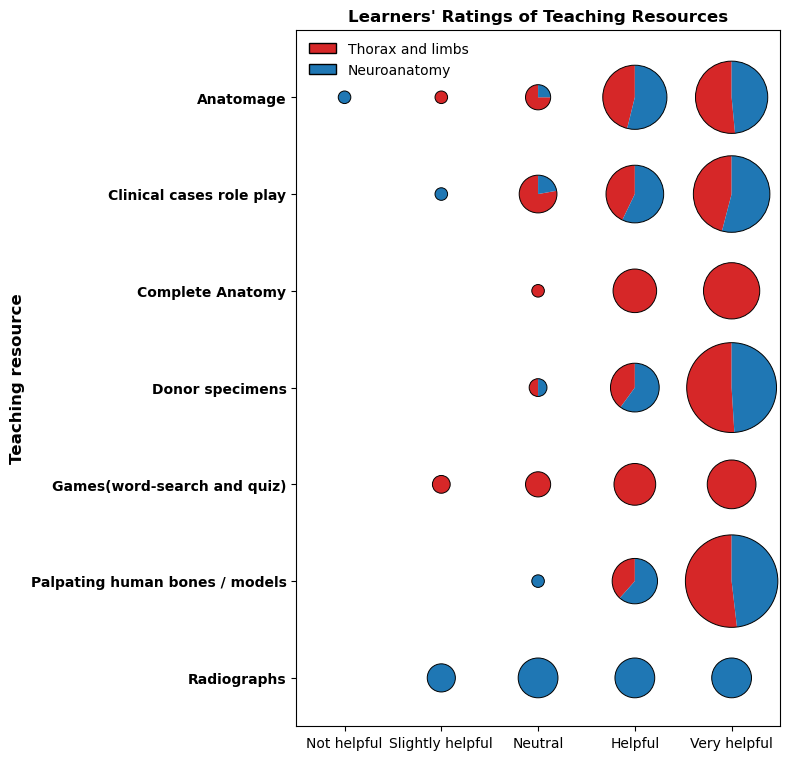

In [12]:
# Order for rows and columns
resource_order = list(resource_items.keys())
rating_order = ["Not helpful", "Slightly helpful", "Neutral", "Helpful", "Very helpful"]

x_map = {lab: i + 1 for i, lab in enumerate(rating_order)}
y_map = {res: len(resource_order) - i for i, res in enumerate(resource_order)}

# Colours for the two sessions
thorax_colour = "#d62728"       # red
neuro_colour = "#1f77b4"        # blue

# Function to draw one split bubble
def draw_split_circle(ax, x, y, n_thorax, n_neuro, scale=0.065):
    total = n_thorax + n_neuro
    if total == 0:
        return
    radius = np.sqrt(total) * scale

    # both sessions contributed
    if n_thorax > 0 and n_neuro > 0:
        frac = n_thorax / total
        angle = 360 * frac
        ax.add_patch(Wedge((x, y), radius, 90, 90 + angle,
                           facecolor=thorax_colour, edgecolor="none"))
        ax.add_patch(Wedge((x, y), radius, 90 + angle, 450,
                           facecolor=neuro_colour, edgecolor="none"))

    # only thorax/limbs
    elif n_thorax > 0:
        ax.add_patch(Circle((x, y), radius,
                            facecolor=thorax_colour, edgecolor="none"))
    # only neuroscience
    elif n_neuro > 0:
        ax.add_patch(Circle((x, y), radius, facecolor=neuro_colour, edgecolor="none"))
    # outline
    ax.add_patch(Circle((x, y), radius, facecolor="none", edgecolor="black", linewidth=0.7))

# Create figure
fig, ax = plt.subplots(figsize=(8, 18))

for resource in resource_order:
    for rating in rating_order:
        temp = resource_dist[
            (resource_dist["Resource"] == resource) &
            (resource_dist["Rating_label"] == rating)
        ]
        n_thorax = temp.loc[temp["Session"] == "Thorax and limbs", "Count"].sum()
        n_neuro = temp.loc[temp["Session"] == "Neuroscience", "Count"].sum()

        draw_split_circle(
            ax,
            x=x_map[rating],
            y=y_map[resource],
            n_thorax=n_thorax,
            n_neuro=n_neuro)

# Axes formatting
ax.set_xlim(0.5, 5.5)
ax.set_ylim(0.5, len(resource_order) + 0.7)
ax.set_aspect("equal", adjustable="box")

ax.set_xticks(range(1, 6))
ax.set_xticklabels(rating_order, rotation=0,)
ax.set_yticks(range(1, len(resource_order) + 1))
ax.set_yticklabels(resource_order[::-1], fontweight="bold")
ax.set_ylabel("Teaching resource", fontsize=12, fontweight="bold")
ax.set_title("Learners' Ratings of Teaching Resources", fontweight="bold", fontsize=12)

ax.grid(False)

# Session legend
session_legend = [
    Patch(facecolor=thorax_colour, edgecolor="black", label="Thorax and limbs"),
    Patch(facecolor=neuro_colour, edgecolor="black", label="Neuroanatomy")
]
ax.legend(handles=session_legend, frameon=False, loc="upper left")

plt.tight_layout()
#plt.savefig("Figure3_split_bubble_plot.png", dpi=600, bbox_inches="tight")
#plt.savefig("Figure3_split_bubble_plot.pdf", bbox_inches="tight")
plt.show()

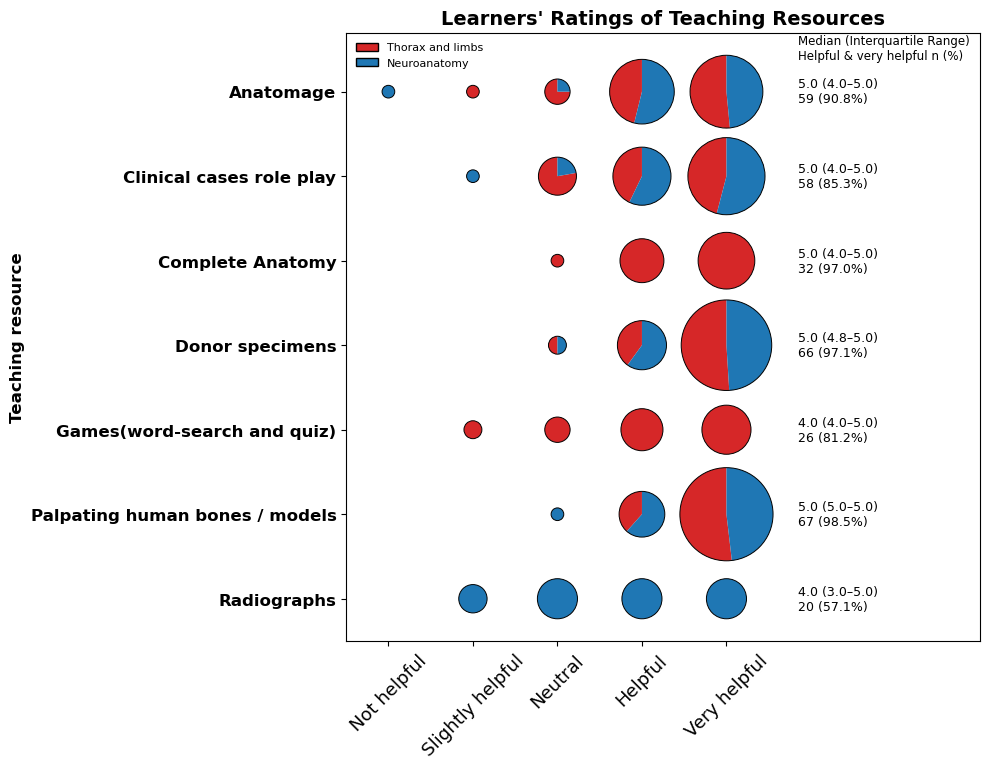

In [13]:
# Order for rows and columns
resource_order = list(resource_items.keys())
rating_order = ["Not helpful", "Slightly helpful", "Neutral", "Helpful", "Very helpful"]

x_map = {lab: i + 1 for i, lab in enumerate(rating_order)}
y_map = {res: len(resource_order) - i for i, res in enumerate(resource_order)}

# Colours for the two sessions
thorax_colour = "#d62728"       # red
neuro_colour = "#1f77b4"        # blue

# Function to draw one split bubble
def draw_split_circle(ax, x, y, n_thorax, n_neuro, scale=0.075):
    total = n_thorax + n_neuro
    if total == 0:
        return
    radius = np.sqrt(total) * scale

    # both sessions contributed
    if n_thorax > 0 and n_neuro > 0:
        frac = n_thorax / total
        angle = 360 * frac
        ax.add_patch(Wedge((x, y), radius, 90, 90 + angle,
                           facecolor=thorax_colour, edgecolor="none"))
        ax.add_patch(Wedge((x, y), radius, 90 + angle, 450,
                           facecolor=neuro_colour, edgecolor="none"))

    # only thorax/limbs
    elif n_thorax > 0:
        ax.add_patch(Circle((x, y), radius,
                            facecolor=thorax_colour, edgecolor="none"))
    # only neuroscience
    elif n_neuro > 0:
        ax.add_patch(Circle((x, y), radius, facecolor=neuro_colour, edgecolor="none"))
    # outline
    ax.add_patch(Circle((x, y), radius, facecolor="none", edgecolor="black", linewidth=0.7))

# Create figure
fig, ax = plt.subplots(figsize=(10, 20))

for resource in resource_order:
    for rating in rating_order:
        temp = resource_dist[
            (resource_dist["Resource"] == resource) &
            (resource_dist["Rating_label"] == rating)
        ]
        n_thorax = temp.loc[temp["Session"] == "Thorax and limbs", "Count"].sum()
        n_neuro = temp.loc[temp["Session"] == "Neuroscience", "Count"].sum()

        draw_split_circle(
            ax,
            x=x_map[rating],
            y=y_map[resource],
            n_thorax=n_thorax,
            n_neuro=n_neuro
        )

# Axes formatting
ax.set_xlim(0.5, 8)
ax.set_ylim(0.5, len(resource_order) + 0.7)
ax.set_aspect("equal", adjustable="box")

ax.set_xticks(range(1, 6))
ax.set_xticklabels(rating_order, rotation=45,fontsize=13)
ax.set_yticks(range(1, len(resource_order) + 1))
ax.set_yticklabels(resource_order[::-1], fontweight="bold", fontsize=12)
ax.set_ylabel("Teaching resource", fontsize=12, fontweight="bold")
ax.set_title("Learners' Ratings of Teaching Resources", fontweight="bold", fontsize=14)

ax.grid(False)

# Session legend
session_legend = [
    Patch(facecolor=thorax_colour, edgecolor="black", label="Thorax and limbs"),
    Patch(facecolor=neuro_colour, edgecolor="black", label="Neuroanatomy")
]
ax.legend(handles=session_legend, frameon=False, loc="upper left", fontsize=8)

# Adding a right-side summary column to the figure 
ax.text(5.85, len(resource_order) + 0.35, 
        "Median (Interquartile Range)\nHelpful & very helpful n (%)",ha="left", va="bottom", fontsize=8.5)

#loop to add summary for each resource
for resource in resource_order:
    row = resource_summary_all[resource_summary_all["Resource"] == resource]

    if row.empty:
        ax.text(5.85,y_map[resource],
            "No data",ha="left",va="center",fontsize=9)
        continue

    median_iqr = row["Median (IQR)"].values[0]
    helpful_n = int(row["Helpful or very helpful n"].values[0])
    helpful_pct = row["Helpful or very helpful %"].values[0]

    ax.text(5.85, y_map[resource],
        f"{median_iqr}\n{helpful_n} ({helpful_pct:.1f}%)",
        ha="left", va="center",fontsize=9)

plt.tight_layout()
#plt.savefig("Figure3_split_bubble_plot.png", dpi=600, bbox_inches="tight")
#plt.savefig("Figure3_split_bubble_plot.pdf", bbox_inches="tight")
plt.show()

In [14]:
# Saving Figure 3 resource usefulness Excel tables

# Add percentages to the long distribution table
resource_dist_excel = resource_dist.copy()

resource_dist_excel["Total rated within resource/session"] = (
    resource_dist_excel.groupby(["Resource", "Session"])["Count"].transform("sum"))

resource_dist_excel["% within resource/session"] = np.where(
    resource_dist_excel["Total rated within resource/session"] > 0,
    round(resource_dist_excel["Count"] / resource_dist_excel["Total rated within resource/session"] * 100, 1),
    0)

# Building the overall summary table for discussion
summary_rows = []

for resource in resource_order:
    temp = resource_dist[resource_dist["Resource"] == resource]

    # Expand counts back into rating values
    values = np.repeat(temp["Rating_num"], temp["Count"])

    total = len(values)

    if total == 0:
        summary_rows.append({
            "Resource": resource,
            "Total rated": 0,
            "Median": np.nan,
            "Q1": np.nan,
            "Q3": np.nan,
            "Median (IQR)": "No ratings"
        })
        continue

    counts = pd.Series(values).value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)

    median = np.median(values)
    q1 = np.percentile(values, 25)
    q3 = np.percentile(values, 75)

    helpful_n = int((values >= 4).sum())
    not_helpful_n = int((values == 1).sum())
    low_rating_n = int((values <= 2).sum())

    summary_rows.append({
        "Resource": resource,
        "Total rated": total,

        "Not helpful n": int(counts[1]),
        "Not helpful %": round(counts[1] / total * 100, 1),
        "Not helpful n (%)": f"{int(counts[1])} ({counts[1] / total * 100:.1f}%)",

        "Slightly helpful n": int(counts[2]),
        "Slightly helpful %": round(counts[2] / total * 100, 1),
        "Slightly helpful n (%)": f"{int(counts[2])} ({counts[2] / total * 100:.1f}%)",

        "Neutral n": int(counts[3]),
        "Neutral %": round(counts[3] / total * 100, 1),
        "Neutral n (%)": f"{int(counts[3])} ({counts[3] / total * 100:.1f}%)",

        "Helpful n": int(counts[4]),
        "Helpful %": round(counts[4] / total * 100, 1),
        "Helpful n (%)": f"{int(counts[4])} ({counts[4] / total * 100:.1f}%)",

        "Very helpful n": int(counts[5]),
        "Very helpful %": round(counts[5] / total * 100, 1),
        "Very helpful n (%)": f"{int(counts[5])} ({counts[5] / total * 100:.1f}%)",

        "Rating ≤2 n": low_rating_n,
        "Rating ≤2 %": round(low_rating_n / total * 100, 1),
        "Rating ≤2 n (%)": f"{low_rating_n} ({low_rating_n / total * 100:.1f}%)",

        "Helpful/very helpful n": helpful_n,
        "Helpful/very helpful %": round(helpful_n / total * 100, 1),
        "Helpful/very helpful n (%)": f"{helpful_n} ({helpful_n / total * 100:.1f}%)",

        "Median": median,
        "Q1": q1, "Q3": q3,
        "Median (IQR)": f"{median:.1f} ({q1:.1f}–{q3:.1f})"
    })

resource_summary_table = pd.DataFrame(summary_rows)

display(resource_dist_excel)
display(resource_summary_table)

# Save both sheets into one Excel file
output_file = "Figure3_teaching_resource_usefulness_tables.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    resource_dist_excel.to_excel(writer, sheet_name="Distribution_long", index=False)
    resource_summary_table.to_excel(writer, sheet_name="Resource_summary", index=False)

,Resource,Session,Rating_num,Rating_label,Count,Total rated within resource/session,% within resource/session
0,Anatomage,Thorax and limbs,1,Not helpful,0,33,0.0
1,Anatomage,Thorax and limbs,2,Slightly helpful,1,33,3.0
2,Anatomage,Thorax and limbs,3,Neutral,3,33,9.1
3,Anatomage,Thorax and limbs,4,Helpful,12,33,36.4
4,Anatomage,Thorax and limbs,5,Very helpful,17,33,51.5
...,...,...,...,...,...,...,...
65,Radiographs,Neuroscience,1,Not helpful,0,35,0.0
66,Radiographs,Neuroscience,2,Slightly helpful,5,35,14.3
67,Radiographs,Neuroscience,3,Neutral,10,35,28.6
68,Radiographs,Neuroscience,4,Helpful,10,35,28.6


,Resource,Total rated,Not helpful n,Not helpful %,Not helpful n (%),Slightly helpful n,Slightly helpful %,Slightly helpful n (%),Neutral n,Neutral %,...,Rating ≤2 n,Rating ≤2 %,Rating ≤2 n (%),Helpful/very helpful n,Helpful/very helpful %,Helpful/very helpful n (%),Median,Q1,Q3,Median (IQR)
0,Anatomage,65,1,1.5,1 (1.5%),1,1.5,1 (1.5%),4,6.2,...,2,3.1,2 (3.1%),59,90.8,59 (90.8%),5.0,4.00,5.0,5.0 (4.0–5.0)
1,Clinical cases role play,68,0,0.0,0 (0.0%),1,1.5,1 (1.5%),9,13.2,...,1,1.5,1 (1.5%),58,85.3,58 (85.3%),5.0,4.00,5.0,5.0 (4.0–5.0)
2,Complete Anatomy,33,0,0.0,0 (0.0%),0,0.0,0 (0.0%),1,3.0,...,0,0.0,0 (0.0%),32,97.0,32 (97.0%),5.0,4.00,5.0,5.0 (4.0–5.0)
3,Donor specimens,68,0,0.0,0 (0.0%),0,0.0,0 (0.0%),2,2.9,...,0,0.0,0 (0.0%),66,97.1,66 (97.1%),5.0,4.75,5.0,5.0 (4.8–5.0)
4,Games(word-search and quiz),32,0,0.0,0 (0.0%),2,6.2,2 (6.2%),4,12.5,...,2,6.2,2 (6.2%),26,81.2,26 (81.2%),4.0,4.00,5.0,4.0 (4.0–5.0)
5,Palpating human bones / models,68,0,0.0,0 (0.0%),0,0.0,0 (0.0%),1,1.5,...,0,0.0,0 (0.0%),67,98.5,67 (98.5%),5.0,5.00,5.0,5.0 (5.0–5.0)
6,Radiographs,35,0,0.0,0 (0.0%),5,14.3,5 (14.3%),10,28.6,...,5,14.3,5 (14.3%),20,57.1,20 (57.1%),4.0,3.00,5.0,4.0 (3.0–5.0)


## Figure 4: Clinical applicability

In [15]:
# Figure 4A: Likelihood of using knowledge in practice

#the name of the column in my excel sheet that contains that response
practice_col = "Use_knowledge_in_practice"

# Labels for 1–5 scale
practice_labels = {
    1: "Very unlikely",
    2: "Unlikely",
    3: "Neutral",
    4: "Likely",
    5: "Very likely"}

# Convert responses to numeric if needed
practice_values = analysis_data[practice_col].copy()

# If the column already contains numbers, this will work directly
practice_numeric = pd.to_numeric(practice_values, errors="coerce")

In [16]:
# If the column contains text labels, map them to numbers
if practice_numeric.notna().sum() == 0:
    reverse_map = {"very unlikely": 1, "unlikely": 2, "neutral": 3, "likely": 4, "very likely": 5}

    practice_numeric = (
        practice_values
        .astype(str)
        .str.strip()
        .str.lower()
        .map(reverse_map))

practice_numeric = practice_numeric.dropna()

# Counts and percentages
counts = practice_numeric.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
percentages = counts / counts.sum() * 100

median = practice_numeric.median()
q1 = practice_numeric.quantile(0.25)
q3 = practice_numeric.quantile(0.75)

likely_n = int((practice_numeric >= 4).sum())
likely_pct = likely_n / len(practice_numeric) * 100

In [17]:
# Summary table
figure4a_summary = pd.DataFrame({
    "Rating": [1, 2, 3, 4, 5],
    "Response": [practice_labels[i] for i in [1, 2, 3, 4, 5]],
    "n": counts.values,
    "%": percentages.round(1).values
})

overall_summary = pd.DataFrame([{
    "Total rated": len(practice_numeric),
    "Median": median,
    "Q1": q1, "Q3": q3,
    "Median (IQR)": f"{median:.1f} ({q1:.1f}–{q3:.1f})",
    "Likely/very likely n": likely_n,
    "Likely/very likely %": round(likely_pct, 1),
    "Likely/very likely n (%)": f"{likely_n} ({likely_pct:.1f}%)"
}])

display(figure4a_summary)
display(overall_summary)

# Save Excel
with pd.ExcelWriter("Figure4_clinical_applicability_summary.xlsx", engine="openpyxl") as writer:
    figure4a_summary.to_excel(writer, sheet_name="Rating_distribution", index=False)
    overall_summary.to_excel(writer, sheet_name="Summary", index=False)

,Rating,Response,n,%
0,1,Very unlikely,0,0.0
1,2,Unlikely,0,0.0
2,3,Neutral,2,3.0
3,4,Likely,19,28.4
4,5,Very likely,46,68.7


,Total rated,Median,Q1,Q3,Median (IQR),Likely/very likely n,Likely/very likely %,Likely/very likely n (%)
0,68,5.0,4.0,5.0,5.0 (4.0–5.0),66,97.1,66 (97.1%)


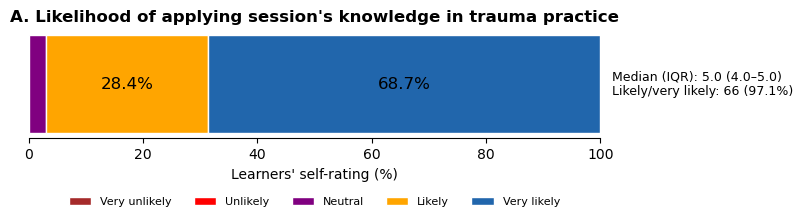

In [18]:
# Plot Figure 4A
fig, ax = plt.subplots(figsize=(8, 2.8))
left = 0

likert_colours = {
    1: "brown",
    2: "red",
    3: "purple",
    4: "orange",
    5: "#2166ac"}

for rating in [1, 2, 3, 4, 5]:
    pct = percentages.loc[rating]

    ax.barh(y=0, width=pct, left=left,
        color=likert_colours[rating], edgecolor="white",
        label=practice_labels[rating])
    #inside bar label
    if pct >= 5:
        ax.text(left + pct / 2, 0, f"{pct:.1f}%",
            ha="center", va="center", fontsize=12)
    left += pct

# Right-side summary
ax.text(102,0,
    f"Median (IQR): {median:.1f} ({q1:.1f}–{q3:.1f})\nLikely/very likely: {likely_n} ({likely_pct:.1f}%)",
    ha="left", va="center",fontsize=9)
 
ax.set_xlim(0, 100)
ax.set_yticks([])
ax.set_xlabel("Learners' self-rating (%)", fontsize=10)
ax.set_title("A. Likelihood of applying session's knowledge in trauma practice", fontweight="bold", fontsize=12)

ax.legend(
    bbox_to_anchor=(0.5, -0.45),
    loc="upper center",
    ncol=5,
    frameon=False,
    fontsize=8,
    title_fontsize=12)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()

#plt.savefig("Figure4A_clinical_applicability.png", dpi=600, bbox_inches="tight")
#plt.savefig("Figure4A_clinical_applicability.pdf", bbox_inches="tight")
plt.show()

In [19]:
#Data for Figure 4B
themes = [
    {
        "theme": "Anatomical structures in relation to trauma",
        "count": 17,
        "comments": [
            "“the location of anatomical structures into real life trauma”",
            "“application of the concept of location and organs and injury”",
            "“linking localised pain to where it is”",
            "“understanding anatomical structures, muscle snd vessels”",
            "“the breakdown and anatomy  of the specimen and how they are in practice”"]},
    {
        "theme": "Neuroanatomy and neurotrauma",
        "count": 14,
        "comments": [
            "“Greater understanding of CSF flow”",
            "“identifying extradural heamotoma”",
            "“Why a bleed/trauma can have such an impact on a patents conscious level”",
            "“Seeing vessels and how injury affects brain”",
            "“cauda equina”",
             "“understanding the brain/CNS?PNS”"]},
    {
        "theme": "Musculoskeletal and joint anatomy",
        "count": 6,
        "comments": [
            "“Manipulation of joints”",
            "“real life structures and completeanatomage for movement of joints”",
            "“joint replacement knowledge”",
            "“how bone injury impacts blood vessels and muscle”",
            "“use of rotatory muscles, Brain regions”"]},
    {
        "theme": "Anatomical visualisation and recognition",
        "count": 9,
        "comments": [
            "“being able to see the real anatomy”",
            "“how structures look in real life”",
            "“all of it gives you the real life context”",
            "“case role-play. Anatomage games”",
            "“Anatomy of display of specimens”"]},
    {
        "theme": "Non-specific",
        "count": 3,
        "comments": [
            "“all”",
            "“Knolwedge gained”",
            "“Seconories”"]}
]

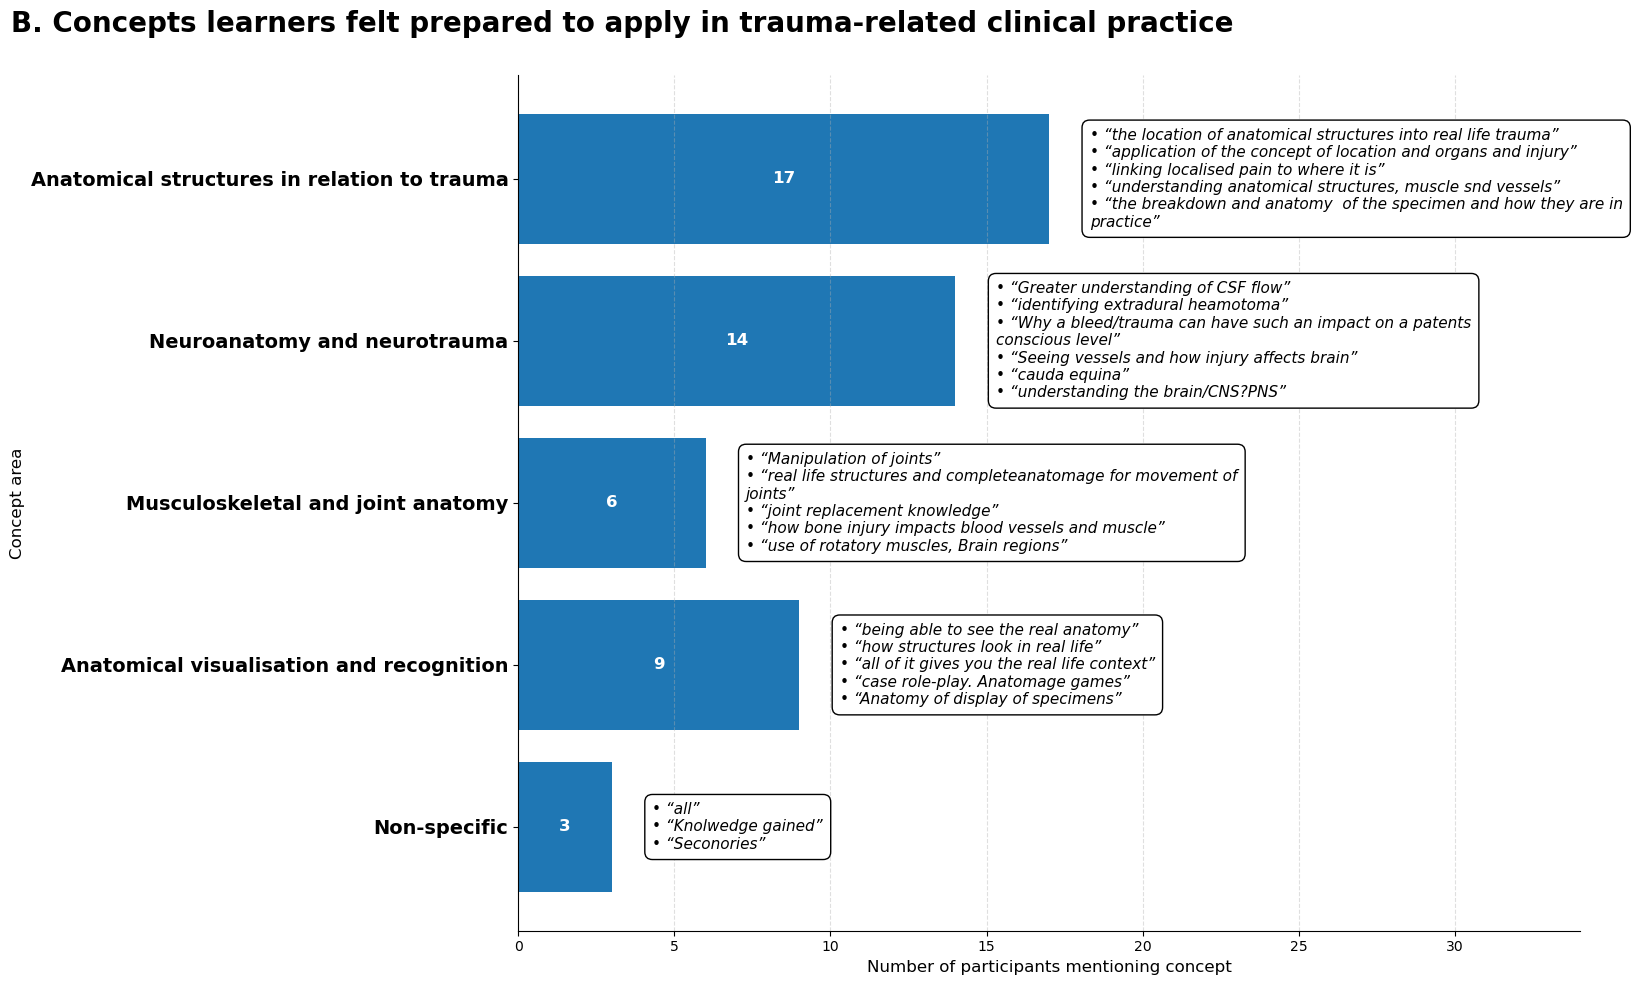

In [23]:
#Prepare plotting objects
theme_names = [t["theme"] for t in themes]
counts = [t["count"] for t in themes]

# Reverse so first theme appears at top
theme_names = theme_names[::-1]
counts = counts[::-1]
themes_reversed = themes[::-1]

#Create figure
fig, ax = plt.subplots(figsize=(16, 10))
bars = ax.barh(theme_names, counts)

# Put participant counts inside the bars
ax.bar_label(bars,
    labels=[str(c) for c in counts],
    label_type="center",
    fontsize=12, fontweight="bold", color="white")

# Add count labels and italic comment boxes close to each bar
for bar, theme_info in zip(bars, themes_reversed):
    count = theme_info["count"]
    y_pos = bar.get_y() + bar.get_height() / 2

    # Join comments into one text block
    comment_text = "\n".join(
        [textwrap.fill(f"• {comment}", width=65) for comment in theme_info["comments"]])

    # Comment box starts after the count
    ax.text(count + 1.3, y_pos, comment_text,
        va="center", ha="left",
        fontsize=11, fontstyle="italic",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="black"))

# Give extra room on the right for the text boxes
ax.set_xlim(0, max(counts) + 17)

ax.set_xlabel("Number of participants mentioning concept", fontsize=12)
ax.set_ylabel("Concept area", fontsize=12)
#concept area text font
ax.tick_params(axis="y", labelsize=14)
for label in ax.get_yticklabels():
    label.set_fontweight("bold")
#ax.set_title("B. Concepts learners felt prepared to apply in trauma-related clinical practice",
    #fontsize=18, weight="bold", pad=10)

# Figure-level title starts from the far left edge of the whole image because the previous ax.set_title code starts it from the middle
fig.text(0.01, 0.98,
    "B. Concepts learners felt prepared to apply in trauma-related clinical practice",
    ha="left", va="top", fontsize=20,fontweight="bold")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.4)

#plt.tight_layout()
plt.tight_layout(rect=[0, 0, 1, 0.93])

#plt.savefig("Figure_4B_horizontal_bar_comments.png", dpi=600, bbox_inches="tight")
#plt.savefig("Figure_4B_horizontal_bar_comments.pdf", bbox_inches="tight")

plt.show()

In [25]:
from PIL import Image

# Load saved high-resolution figures
fig4a = Image.open("Figure4A_clinical_applicability.png").convert("RGB")
fig4b = Image.open("Figure_4B_horizontal_bar_comments.png").convert("RGB")

# Make both panels same width
target_width = max(fig4a.width, fig4b.width)

def resize_to_width(img, width):
    ratio = width / img.width
    new_height = int(img.height * ratio)
    return img.resize((width, new_height), Image.LANCZOS)

fig4a = resize_to_width(fig4a, target_width)
fig4b = resize_to_width(fig4b, target_width)

# Space between panels
gap = 60

# Create combined canvas
combined_height = fig4a.height + gap + fig4b.height
combined = Image.new("RGB", (target_width, combined_height), "white")

# Paste Figure 4A
combined.paste(fig4a, (0, 0))

# Paste Figure 4B below
combined.paste(fig4b, (0, fig4a.height + gap))

# Save high-quality combined figure
combined.save("Figure4_combined_clinical_applicability.png", dpi=(600, 600))
combined.save("Figure4_combined_clinical_applicability.tiff", dpi=(600, 600), compression="tiff_lzw")

In [26]:
combined.save("Figure4_combined_clinical_applicability.pdf", "PDF",resolution=600)

## Figure 5: Other Open-ended Questions

In [75]:
themes = {#Theme 1
    "Hands-on engagement supported anatomical understanding": {"count": 33,
        "subthemes": {
            "Appreciation of cadaveric/preserved specimens": {"count": 13,
                "comments": [
                    "use of cadaveric specimen",
                    "Being able to physically see and move cadavers to fully understand function",
                    "Donors helped see real anatomy",
                    "visualising structures all together"]
            },
            "Palpation, bones/models and tactile handling": {"count": 5,
                "comments": [
                    "Palpations of real bones and models helped me visualise",
                    "hands on, real bones and strutures",
                    "the anatomy of the body being able to touch it"]
            },
            "Identification, flags and labels": {"count": 8,
                "comments": [
                    "Demonstration of identifying features on cadaver",
                    "using cadaveric structures with labels to identify them",
                    "Identifying structures on cadavers"]
            },
            "Real anatomical context, size and relationships": {"count": 7,
                "comments": [
                    "Specimens to put into perspective",
                    "Seeing the real Human anatomy",
                    "Spinal vertebrae + where they're located in real life", 
                    "exploring anatomy on real life organs/limbs"]}}
    },

    #Theme 2
    "Multimodal and technology-enhanced resources enriched trauma anatomy learning": {"count": 11,
        "subthemes": {
            "Anatomage/app/digital anatomy tools": {"count": 5,
                "comments": [
                    "Anatomage games",
                    "The anatomage",
                    "Practical and anatomage",
                    "the app",]
            },
            "Diagrams/images and visual resources": {"count": 2,
                "comments": [
                    "daigram iamges of the cadaver",
                    "diagrams and real life samples",]
            },
            "Preparatory/station-based resources": {"count": 4,
                "comments": [
                    "pre-session activity",
                    "station 1 and 2 of neuro",
                    "combination of all"]}}
    },

    #Theme 3
    "Trauma-focused anatomy, pathology and clinical application": {"count": 10,
        "subthemes": {
            "Neurotrauma/neurovascular and spinal anatomy": {"count": 6,
                "comments": [
                    "brain on table 5, spinal cord",
                    "Seeing structures of brain + spinal cord",
                    "Identifying blood vessels & circles of wills",
                    "spinal vertebrae + where they're located in real life",]
            },
            "Pathology, procedures and clinical application": {"count": 3,
                "comments": [
                    "Subdural hematoma",
                    "anatomage for learning epidural injection and pathology",
                    "nerves. Helpful for evidencebased practice"]
            },
            "Case-based links to real injuries": {"count": 1,
                "comments": [
                    "case studies because it links with theory and real life injuries"]}}
    },

    #Theme 4
    "Interaction and collaborative learning supported engagement": {"count": 11,
        "subthemes": {
            "Facilitator/tutor input": {"count": 5,
                "comments": [
                    "Session faciliator",
                    "interacting and explaining the specimens",
                    "well run session. Very helpful tutor"]
            },
            "Group work and discussion": {"count": 3,
                "comments": [
                    "The instructors, Group discussion, the structures",
                    "Group work and discussion",
                    "lab session & group discussion"]
            },
            "Interactive and engaging delivery": {"count": 3,
                "comments": [
                    "very realistic. Interactive",
                    "It was a new experience, useful and interactive",
                    "session was very interactive, visual and auditory learning"]}}
    },

    #Theme 5
    "Overall acceptability and perceived value of the session": {
        "count": 24,
        "subthemes": {
            "Positive general appraisal": {
                "count": 8,
                "comments": [
                    "Excellent session",
                    "Great session",
                    "Great work! Thank you",
                    "Brillant session"]
            },
            "Perceived usefulness/informativeness": {
                "count": 6,
                "comments": [
                    "very useful session",
                    "Very informative and engaging",
                    "Thank you / Very informative",
                    "very good time & learning"]
            },
            "Enjoyment and appreciation": {
                "count": 7,
                "comments": [
                    "thoroughly enjoyed every aspect",
                    "Thank you!",
                    "Thoroughly enjoyed!"]
            },
            "Desire for longer or repeat sessions": {
                "count": 3,
                "comments": [
                    "All but needed longer",
                    "hope to do it again",
                    "Very good session. Should be a full day!"]}}
    }
}

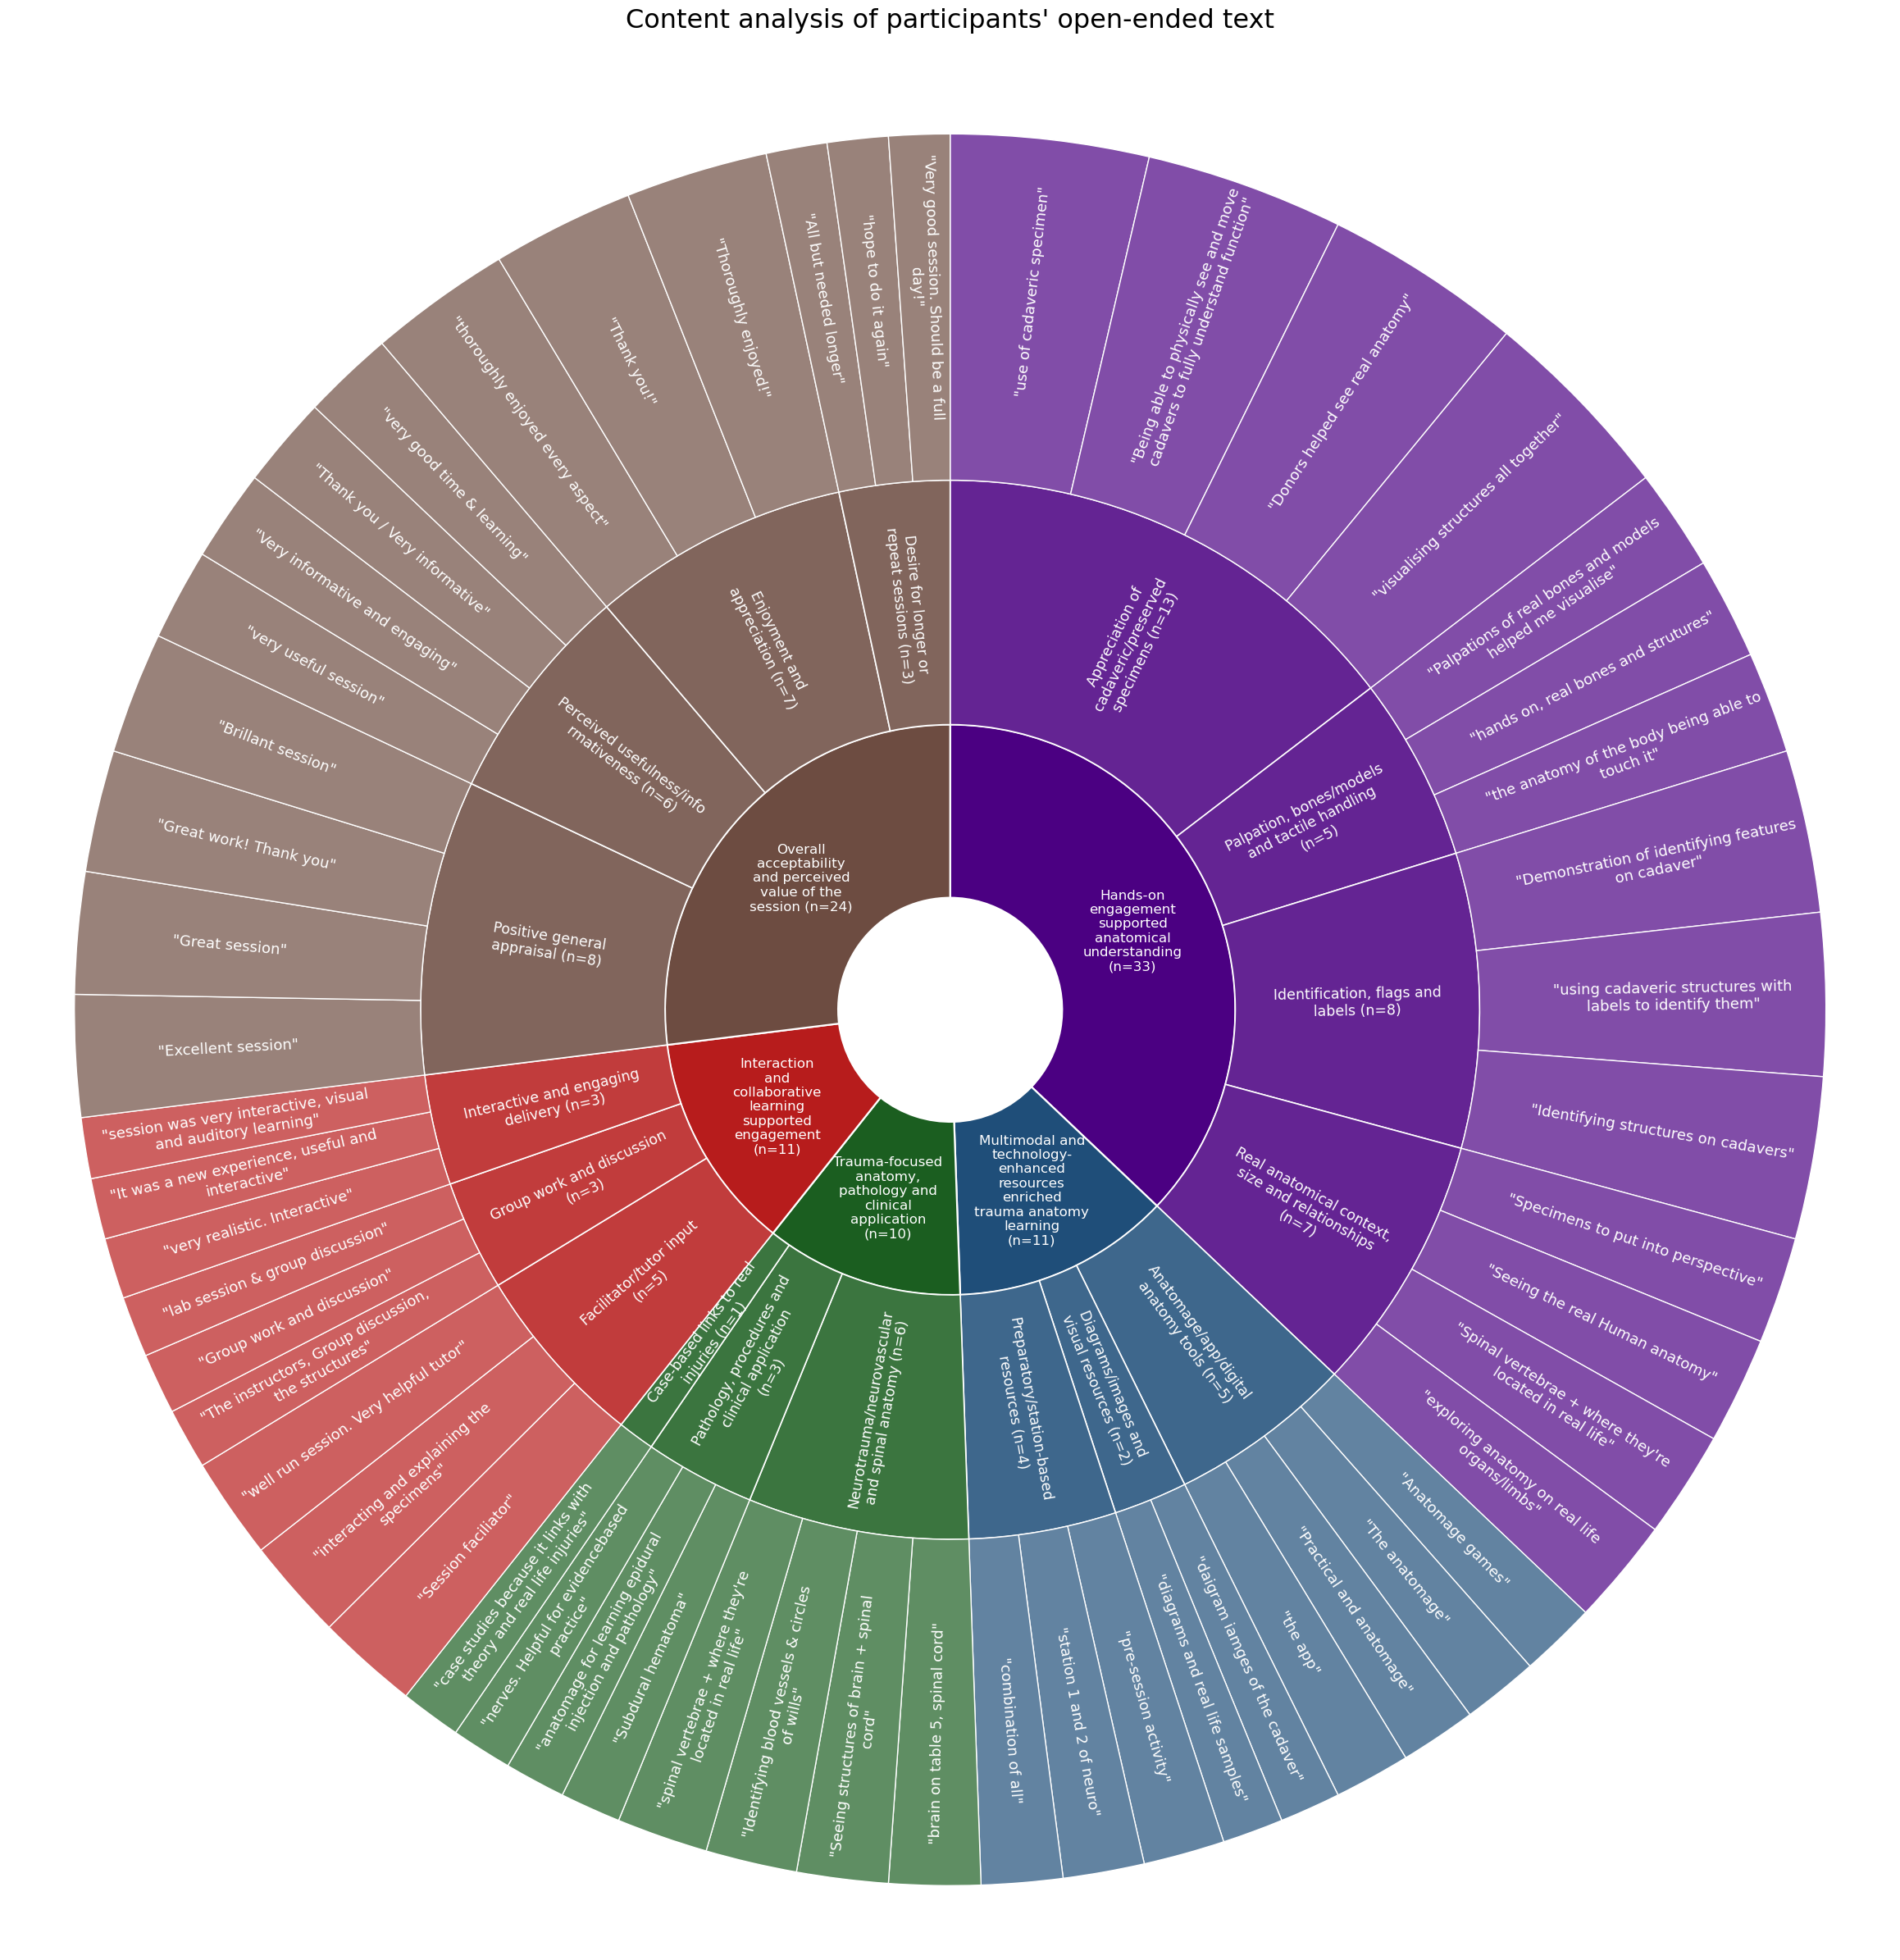

In [98]:
theme_colours = ["#4B0082", "#1F4E79", "#1B5E20", "#B71C1C", "#6D4C41"]

def lighten(colour, amount):
    c = np.array(mcolors.to_rgb(colour))
    return tuple(c + (1 - c) * amount)

def wrap(text, width):
    return "\n".join(textwrap.wrap(str(text), width=width))

def add_text(ax, text, theta1, theta2, r, fontsize, rotate=True, reverse=False):
    angle = (theta1 + theta2) / 2
    x = r * np.cos(np.deg2rad(angle))
    y = r * np.sin(np.deg2rad(angle))

    #I am using this for the way the text will appear in the circle
    if not rotate:
        rotation = 0
    else:
        if reverse:
            rotation = angle + 180
        else:
            rotation = angle
            if 90 < angle < 270:
                rotation += 180

    ax.text(x, y, text, ha="center", va="center", rotation=rotation, 
            rotation_mode="anchor", fontsize=fontsize, color="white")
#counts
total_count = sum(theme["count"] for theme in themes.values())

r0, r1, r2, r3 = 0.22, 0.56, 1.04, 1.72

fig, ax = plt.subplots(figsize=(24, 24), subplot_kw=dict(aspect="equal"))
start_angle = 90

#df needed for the plotting of two themes as teh initial plot rotated the text
reverse_label_themes = {"Interaction and collaborative learning supported engagement",
    "Overall acceptability and perceived value of the session", "Trauma-focused anatomy, pathology and clinical application"}

#Loop for the plotting of the chart
for i, (theme_name, theme_data) in enumerate(themes.items()):
    base = theme_colours[i]
    reverse_labels = theme_name in reverse_label_themes #calling my df
    theme_count = theme_data["count"]
    theme_span = 360 * theme_count / total_count

    t1 = start_angle
    t2 = start_angle - theme_span

    ax.add_patch(
        Wedge((0, 0), r1, t2, t1, width=r1-r0, facecolor=base, edgecolor="white", linewidth=1.6))

    add_text(ax, wrap(f"{theme_name}\n(n={theme_count})", 14),
        t2, t1,(r0+r1)/2, fontsize=12, rotate=False)
    sub_start = t1

    for subtheme_name, subtheme_data in theme_data["subthemes"].items():
        sub_count = subtheme_data["count"]
        sub_span = theme_span * sub_count / theme_count

        s1 = sub_start
        s2 = sub_start - sub_span

        ax.add_patch(
            Wedge((0, 0), r2, s2, s1, width=r2-r1, facecolor=lighten(base, 0.14),
                edgecolor="white",linewidth=1.2))

        add_text(ax,wrap(f"{subtheme_name}\n(n={sub_count})", 25),
            s2, s1, (r1+r2)/2, fontsize=12.5, rotate=True, reverse=reverse_labels) 

        comment_start = s1
        comments = subtheme_data["comments"]

        for comment in comments:
            comment_span = sub_span / len(comments)
            c1 = comment_start
            c2 = comment_start - comment_span

            ax.add_patch(
                Wedge((0, 0), r3, c2, c1, width=r3-r2, facecolor=lighten(base, 0.30),
                    edgecolor="white",linewidth=1.0))

            add_text(ax,wrap(f'"{comment}"', 38), #to make the text longer in length in the chart
                c2, c1, (r2+r3)/2 + 0.04, fontsize=13, rotate=True, reverse=reverse_labels)

            comment_start = c2

        sub_start = s2

    start_angle = t2

ax.add_artist(plt.Circle((0, 0), 0.18, color="white"))

ax.set_xlim(-1.85, 1.85)
ax.set_ylim(-1.85, 1.85)
ax.axis("off")

plt.title("Content analysis of participants' open-ended text",
    fontsize=23,pad=35)

plt.tight_layout()
plt.savefig("Fig5_opentext_content analysis.png", dpi=600, bbox_inches="tight")
plt.savefig("Fig5_opentext_content analysis.pdf", bbox_inches="tight")
plt.show()

In [ ]:
## Design my framework figure